# Etsy marketplace analysis: which niches and price points are worth targeting?

## Business question
> **Which niches and price points are worth targeting on Etsy's digital and printable wall-art market, and what separates best-selling listings from the rest?**

**Data.** Two best-seller list scrapes (June 2024 and July 2024) collected with Octoparse. The raw files are not in this repo because they were scraped and contain seller identifiers. See `README.md` for how to run the notebook on your own data, and `sample/` for an anonymised sample and schema.

**How "best seller" is defined here.** Every row is already on an Etsy best-seller list, so there is no clean "non-best-seller" group. The scrape captured Etsy's live demand badge for each listing (for example *"In 20+ carts"* or *"3 people bought this in the last 24 hours"*). I call a listing **high-demand** if its badge shows **20 or more carts, or a recent purchase count**. Everything else is "rest". This measures demand at the moment of the scrape, not lifetime sales, and I treat it as a proxy.

**Notebook map:** 1 Load → 2 Clean (duplicates, missing values, price parsing, type fixes) → 3 Explore → 4 SQL section (SQLite) → 5 Findings and recommendation → 6 Anonymised sample export.

In [1]:
import re, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")            # raw files live here locally and are git-ignored
IMG_DIR = Path("images"); IMG_DIR.mkdir(exist_ok=True)
SAMPLE_DIR = Path("sample"); SAMPLE_DIR.mkdir(exist_ok=True)

BLUE, GREY, ORANGE = "#2a78d6", "#a9a8a2", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True, "font.size": 10})
pd.set_option("display.width", 140)

## 1. Load the raw files
The two files use different column names, and the scraper left some columns as text. I print only shapes, types and missing-value counts here, never URLs or titles, so no identifiers end up in the committed notebook output.

In [2]:
raw_jun = pd.read_excel(DATA_DIR / "best_seller_jun2024.xlsx")
raw_jul = pd.read_excel(DATA_DIR / "best_seller_jul2024.xlsx")

for name, d in [("June 2024", raw_jun), ("July 2024", raw_jul)]:
    print(f"{name}: {d.shape[0]:,} rows x {d.shape[1]} columns")
    print("  columns:", list(d.columns))

June 2024: 3,139 rows x 10 columns
  columns: ['Plain URL', 'Page_URL', 'status', 'Price USD', 'Title', 'Reviews_ThisItem', 'Shop_Reviews', 'Favorites', 'FAVs_Form', 'Demand State']
July 2024: 1,493 rows x 9 columns
  columns: ['Demand', 'Price', 'Title', 'Reviews Item', 'Reviews Shop', 'Listen on', 'Page_title', 'Original_URL', 'Favorites']


## 2. Cleaning
### 2.1 Map both files to one schema
The listing ID is pulled out of the URL purely so that duplicates can be found. It is dropped before any analysis table or export. Where the June file has no scraped title, the URL slug often still carries the product title (truncated), so I keep it as a fallback text field.

In [3]:
def listing_id(url):
    m = re.search(r"/listing/(\d+)", str(url))
    return m.group(1) if m else np.nan

jun = pd.DataFrame({
    "listing_id": raw_jun["Plain URL"].map(listing_id).fillna(raw_jun["Page_URL"].map(listing_id)),
    "slug": raw_jun["Page_URL"].str.extract(r"/listing/\d+/(.+)$")[0],
    "title": raw_jun["Title"],
    "demand_raw": raw_jun["Demand State"].fillna(raw_jun["status"]),   # demand badge sat in two columns
    "price_raw": raw_jun["Price USD"],
    "item_reviews": raw_jun["Reviews_ThisItem"],
    "shop_reviews": raw_jun["Shop_Reviews"],
    "favorites": raw_jun["Favorites"],
    "listed_raw": np.nan,
    "source": "2024-06",
})
jul = pd.DataFrame({
    "listing_id": raw_jul["Original_URL"].map(listing_id),
    "slug": np.nan,
    "title": raw_jul["Title"],
    "demand_raw": raw_jul["Demand"],
    "price_raw": raw_jul["Price"],
    "item_reviews": raw_jul["Reviews Item"],
    "shop_reviews": raw_jul["Reviews Shop"],
    "favorites": raw_jul["Favorites"],                 # text like "848 favorites"
    "listed_raw": raw_jul["Listen on"],                # text like "Listed on Jul 17, 2024 ... 848 favorites"
    "source": "2024-07",
})
df = pd.concat([jun, jul], ignore_index=True)
log = [("Raw rows, both files stacked", len(df))]
print(f"{len(df):,} rows stacked")

4,632 rows stacked


### 2.2 Missing values (before cleaning)

In [4]:
def missing_table(d, cols):
    t = pd.DataFrame({"missing": d[cols].isna().sum(), "pct_missing": (d[cols].isna().mean() * 100).round(1)})
    return t

missing_table(df, ["title", "slug", "demand_raw", "price_raw", "item_reviews", "shop_reviews", "favorites"])

,missing,pct_missing
title,2254,48.7
slug,1545,33.4
demand_raw,805,17.4
price_raw,726,15.7
item_reviews,385,8.3
shop_reviews,385,8.3
favorites,63,1.4


Reading this table: `title` is missing for a large share of rows, `price_raw` is missing for some, and `demand_raw` is empty when Etsy showed no badge. I handle each differently below rather than dropping rows wholesale, because a missing price should not remove a listing from the demand and niche analysis.

### 2.3 Duplicates
Three kinds of duplicate: fully identical rows, the same listing twice in one file, and the same listing present in both scrapes. For the last case I keep the **July** record because it is the later snapshot.

In [5]:
n_exact = df.drop(columns=[]).duplicated().sum()
print("Exact duplicate rows:", n_exact)

dup_within = df.duplicated(["source", "listing_id"]).sum()
print("Same listing twice within one file:", dup_within)

ids_jun = set(df.loc[df.source == "2024-06", "listing_id"])
ids_jul = set(df.loc[df.source == "2024-07", "listing_id"])
print("Listings that appear in both scrapes:", len(ids_jun & ids_jul))

df = df.drop_duplicates()
log.append(("After dropping exact duplicates", len(df)))

# The July record wins, but it usually has no title or slug. Borrow those from the June record of the same listing first.
june_text = df[df.source == "2024-06"].drop_duplicates("listing_id").set_index("listing_id")[["title", "slug"]]
df = df.sort_values("source", ascending=False).drop_duplicates("listing_id", keep="first")   # July sorts first
for col in ["title", "slug"]:
    df[col] = df[col].fillna(df["listing_id"].map(june_text[col]))
log.append(("After de-duplicating on listing ID (keep latest scrape)", len(df)))
print(f"{len(df):,} unique listings remain; missing listing IDs: {df.listing_id.isna().sum()}")

Exact duplicate rows: 0
Same listing twice within one file: 1
Listings that appear in both scrapes: 663
3,968 unique listings remain; missing listing IDs: 0


### 2.4 Price parsing
Prices are a mix of floats, ints and strings. A trailing `+` (for example `"9.00+"`) means the listing has variations and the price shown is the starting price. I keep that as a flag and parse the number. Missing prices stay missing: I do not impute them.

In [6]:
s = df["price_raw"].astype(str)
df["has_variants"] = s.str.endswith("+")
df["price"] = pd.to_numeric(s.str.replace("+", "", regex=False).str.strip(), errors="coerce")

print("Price values that were text:", int(df.price_raw.map(lambda x: isinstance(x, str)).sum()))
print("Price missing after parsing:", int(df.price.isna().sum()), f"({df.price.isna().mean():.1%})")
print("Non-positive prices:", int((df.price <= 0).sum()))
print(df.price.describe(percentiles=[.01, .5, .9, .99]).round(2).to_string())

Price values that were text: 348
Price missing after parsing: 697 (17.6%)
Non-positive prices: 0
count    3271.00
mean       10.34
std        18.29
min         0.24
1%          1.10
50%         5.74
90%        18.19
99%        95.92
max       255.36


The maximum is far above the median, so I check that the high end is real products (large bundles and custom work) rather than a parsing error. Prices under a dollar are plausible for digital downloads, so I keep them.

In [7]:
print("Listings above $100:", int((df.price > 100).sum()), "| above $200:", int((df.price > 200).sum()))

Listings above $100: 22 | above $200: 5


### 2.5 Hidden missing values and type fixes
**Placeholder zeros.** In the June file, review counts are never blank. Yet hundreds of rows have *both* review counts exactly 0, and never just one of them. A shop with zero reviews appearing on a best-seller list is implausible, and the next cell shows those same rows are also far more likely to be missing a price and a demand badge. I treat them as failed scrapes and set both counts to missing. The July file uses real blanks and has no such zeros.

**Type fixes.**
- `favorites` in the July file is text ("848 favorites"), so I extract the integer.
- `listed_raw` ("Listed on Jul 17, 2024 …") becomes a real date (July file only).
- Review counts become nullable integers so missing values do not force floats.
- The demand badge text is parsed into numbers: carts, recent purchases, views.

In [8]:
sentinel = (df.source == "2024-06") & (df.item_reviews == 0) & (df.shop_reviews == 0)
print(f"Rows with both review counts == 0 (June): {sentinel.sum()}")
print(f"  price missing:        {df.loc[sentinel, 'price'].isna().mean():.1%} for those rows vs {df.loc[~sentinel & (df.source == '2024-06'), 'price'].isna().mean():.1%} for other June rows")
print(f"  demand badge missing: {df.loc[sentinel, 'demand_raw'].isna().mean():.1%} for those rows vs {df.loc[~sentinel & (df.source == '2024-06'), 'demand_raw'].isna().mean():.1%} for other June rows")
df.loc[sentinel, ["item_reviews", "shop_reviews"]] = np.nan

fav_text = df["favorites"].astype(str).str.extract(r"([\d,]+)")[0].str.replace(",", "", regex=False)
df["favorites"] = pd.to_numeric(fav_text, errors="coerce")

df["listed_date"] = pd.to_datetime(df["listed_raw"].astype(str).str.extract(r"Listed on (.+?)\s{2,}")[0], errors="coerce")
print("Listed dates parsed:", df.listed_date.notna().sum(), "| range:", df.listed_date.min().date(), "to", df.listed_date.max().date())

for c in ["item_reviews", "shop_reviews", "favorites"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").round().astype("Int64")

d = df["demand_raw"].fillna("")
df["carts"] = pd.to_numeric(d.str.extract(r"(?i)in (\d+)\+? carts")[0], errors="coerce")
df["bought_recent"] = pd.to_numeric(d.str.extract(r"(\d+) people bought")[0], errors="coerce")
df["views_24h"] = pd.to_numeric(d.str.extract(r"(\d+)\+? views")[0], errors="coerce")

def tier(row):
    if pd.notna(row.bought_recent): return "Bought recently"
    if pd.notna(row.carts): return "In 20+ carts" if row.carts >= 20 else "In 1-19 carts"
    if pd.notna(row.views_24h): return "Views only"
    return "No demand badge" if row.demand_raw is np.nan or str(row.demand_raw) == "nan" else "Low stock only"
df["demand_tier"] = df.apply(tier, axis=1)
df["high_demand"] = (df["bought_recent"].notna() | (df["carts"] >= 20)).astype(int)

print(df[["price", "favorites", "item_reviews", "shop_reviews", "listed_date"]].dtypes.to_string())
print()
print(df["demand_tier"].value_counts().to_string())

Rows with both review counts == 0 (June): 493
  price missing:        40.6% for those rows vs 14.0% for other June rows
  demand badge missing: 40.6% for those rows vs 14.0% for other June rows
Listed dates parsed: 1393 | range: 2023-11-04 to 2024-07-17


price                  float64
favorites                Int64
item_reviews             Int64
shop_reviews             Int64
listed_date     datetime64[us]

demand_tier
In 20+ carts       1535
No demand badge     776
Views only          681
In 1-19 carts       621
Bought recently     317
Low stock only       38


### 2.6 Text for niche tagging (titles)
Scraped titles are missing for many rows. For the June file the URL slug carries a truncated title, so I use `title` first and the slug as a fallback. I measure how much this recovers. No titles are printed.

In [9]:
df["text"] = df["title"].fillna(df["slug"].astype("string").str.replace("-", " ", regex=False)).str.lower()
before = df["title"].notna().mean()
after = df["text"].notna().mean()
print(f"Rows with usable text: {before:.1%} from scraped titles only -> {after:.1%} after slug fallback ({df.text.notna().sum():,} rows)")
df["title_len"] = df["title"].str.len()      # real titles only, not truncated slugs

Rows with usable text: 53.2% from scraped titles only -> 86.0% after slug fallback (3,411 rows)


### 2.7 Cleaning log

In [10]:
log.append(("Final analysis rows", len(df)))
cleaning_log = pd.DataFrame(log, columns=["step", "rows"])
cleaning_log["change"] = cleaning_log["rows"].diff().fillna(0).astype(int)
display(cleaning_log)

df = df.drop(columns=["slug", "listed_raw", "price_raw"])      # drop identifier-bearing / raw columns
df_ids = df.pop("listing_id")                                  # listing ID is not needed past this point
print(f"{len(df):,} rows, {df.shape[1]} columns. Missing after cleaning:")
print(df[["price", "item_reviews", "shop_reviews", "favorites", "text"]].isna().sum().to_string())

,step,rows,change
0,"Raw rows, both files stacked",4632,0
1,After dropping exact duplicates,4632,0
2,After de-duplicating on listing ID (keep lates...,3968,-664
3,Final analysis rows,3968,0


3,968 rows, 16 columns. Missing after cleaning:
price           697
item_reviews    878
shop_reviews    878
favorites       107
text            557


### 2.8 Analysis population
776 listings show **no demand badge at all**. That could mean Etsy genuinely showed none, or that the scraper failed to capture it (the failed-scrape rows found in 2.5 are about three times more likely to lack a badge). Because the two cannot be told apart, the demand analysis uses only listings **with a demand badge**, and section 3.7 re-runs the key results with the no-badge rows added back as "not high-demand".

In [11]:
df_all = df.copy()
df = df[df["demand_tier"] != "No demand badge"].copy()
print(f"Listings with a demand badge (analysis population): {len(df):,} of {len(df_all):,}")
print(f"Priced listings within that population: {df.price.notna().sum():,}")

Listings with a demand badge (analysis population): 3,192 of 3,968
Priced listings within that population: 3,192


## 3. Exploration
### 3.1 What does the demand signal look like?

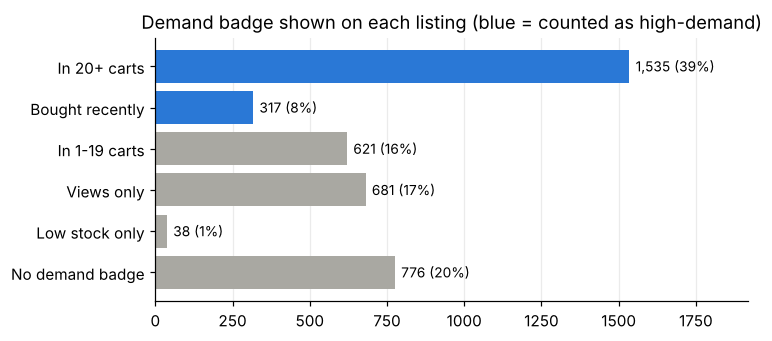

High-demand listings: 1,852 of 3,192 listings that show a badge (58.0%); 46.7% if the 776 no-badge listings are counted as not high-demand
          mean  size
source              
2024-06  0.490  1999
2024-07  0.732  1193


In [12]:
order = ["In 20+ carts", "Bought recently", "In 1-19 carts", "Views only", "Low stock only", "No demand badge"]
t = df_all["demand_tier"].value_counts().reindex(order).dropna()
fig, ax = plt.subplots(figsize=(7, 3.2))
cols = [BLUE if k in ("In 20+ carts", "Bought recently") else GREY for k in t.index]
ax.barh(t.index[::-1], t.values[::-1], color=cols[::-1])
for i, v in enumerate(t.values[::-1]):
    ax.text(v + 20, i, f"{v:,} ({v/len(df_all):.0%})", va="center", fontsize=9)
ax.set_xlim(0, t.max() * 1.25); ax.set_title("Demand badge shown on each listing (blue = counted as high-demand)")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.savefig(IMG_DIR / "demand_tiers.png"); plt.show()
print(f"High-demand listings: {df.high_demand.sum():,} of {len(df):,} listings that show a badge ({df.high_demand.mean():.1%}); "
      f"{df_all.high_demand.mean():.1%} if the {len(df_all) - len(df):,} no-badge listings are counted as not high-demand")
print(df.groupby('source').high_demand.agg(['mean', 'size']).round(3).to_string())

The high-demand share differs a lot between the two scrapes (and most of the July rows have no recoverable title, so they land in "Unknown" when niches are tagged). To stop that mix from distorting the comparisons, **niche and price-band rates below are compared with an expected rate**: the rate you would see if each listing had the high-demand rate of its own source file. The gap is reported in percentage points.

### 3.2 Price distribution

Price percentiles 10/25/50/75/90: [ 2.09  3.45  5.74  9.88 17.84]


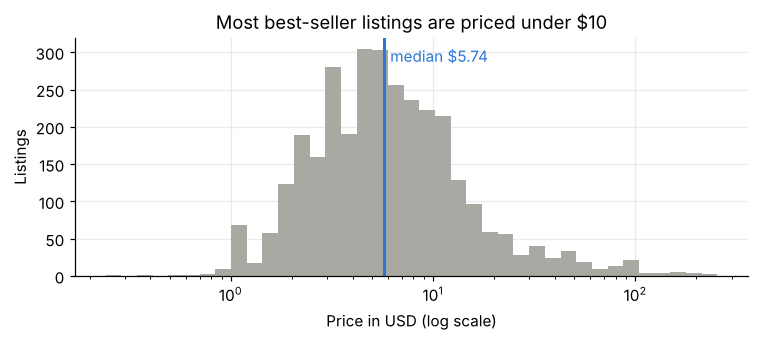

In [13]:
p = df["price"].dropna().to_numpy()
pcts = np.percentile(p, [10, 25, 50, 75, 90])
print("Price percentiles 10/25/50/75/90:", np.round(pcts, 2))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(p, bins=np.logspace(np.log10(max(p.min(), .2)), np.log10(p.max()), 40), color=GREY)
ax.set_xscale("log"); ax.axvline(np.median(p), color=BLUE, lw=2)
ax.text(np.median(p) * 1.07, ax.get_ylim()[1] * .9, f"median ${np.median(p):.2f}", color=BLUE)
ax.set_xlabel("Price in USD (log scale)"); ax.set_ylabel("Listings"); ax.set_title("Most best-seller listings are priced under $10")
plt.tight_layout(); plt.savefig(IMG_DIR / "price_distribution.png"); plt.show()

### 3.3 Niches
There is no category column, so I tag niches from title keywords using an ordered rule list (first match wins, so a format like *SVG* outranks a theme like *vintage*). The rules were written before looking at demand rates and are not tuned to them. Rows with no text are kept as "Unknown" so the coverage gap stays visible.

In [14]:
RULES = [
    ("Clipart / SVG / PNG",             r"\bsvg\b|\bpng\b|clipart|sublimation|cricut|cut file|digital paper"),
    ("Coloring / kids activity",        r"coloring|handprint|activity|worksheet|craft"),
    ("Templates / cards / planners",    r"template|planner|canva|editable|card|invitation"),
    ("Christian / Bible",               r"bible|christian|jesus|scripture|faith|verse"),
    ("Nursery / baby / kids",           r"nursery|baby|kids|toddler|\bgirl|\bboy"),
    ("Seasonal (Easter, spring, holiday)", r"easter|spring|christmas|halloween|bunny|valentine|mother|summer|\bfall\b|autumn|holiday"),
    ("Kitchen / bathroom / bar",        r"bathroom|kitchen|\bbar\b|laundry"),
    ("Vintage / retro / gallery wall",  r"vintage|retro|antique|oil painting|gallery|eclectic|maximalist|moody"),
    ("Floral / botanical / landscape",  r"floral|flower|botanical|wildflower|landscape|nature"),
    ("Abstract / minimalist / boho",    r"abstract|minimalist|modern|neutral|boho|aesthetic"),
    ("Other wall art",                  r"wall art|print|poster|decor"),
]
def tag_niche(text):
    if not isinstance(text, str): return "Unknown (no title)"
    for name, pat in RULES:
        if re.search(pat, text): return name
    return "Other"
df["niche"] = df["text"].map(tag_niche)

def wilson(k, n, z=1.96):
    # 95% Wilson interval for a proportion
    if n == 0: return (np.nan, np.nan)
    ph = k / n; den = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / den
    h = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

print("High-demand rate by source file:", df.groupby("source").high_demand.mean().round(3).to_dict())

def rate_table(data, g):
    # 'expected' = the high-demand rate each listing would have if it matched its own source file's overall rate
    data = data.assign(expected=data["source"].map(data.groupby("source").high_demand.mean()))
    t = (data.groupby(g, observed=True).agg(listings=("high_demand", "size"), high_demand_n=("high_demand", "sum"),
                                          expected_rate=("expected", "mean"),
                                          median_price=("price", "median"), median_favorites=("favorites", lambda s: s.median()))
           .assign(high_demand_rate=lambda x: x.high_demand_n / x.listings))
    ci = t.apply(lambda r: wilson(r.high_demand_n, r.listings), axis=1, result_type="expand")
    t["ci_lo"], t["ci_hi"] = ci[0], ci[1]
    t["lift_pts"] = 100 * (t.high_demand_rate - t.expected_rate)       # percentage points above expected
    t["lift_lo"], t["lift_hi"] = 100 * (t.ci_lo - t.expected_rate), 100 * (t.ci_hi - t.expected_rate)
    return t

niche = rate_table(df, "niche").sort_values("lift_pts", ascending=False)
display(niche.drop(columns=["high_demand_n", "ci_lo", "ci_hi"]).round(3))

High-demand rate by source file: {'2024-06': 0.49, '2024-07': 0.732}


,listings,expected_rate,median_price,median_favorites,high_demand_rate,lift_pts,lift_lo,lift_hi
niche,,,,,,,,
Kitchen / bathroom / bar,142,0.636,6.230,1146.5,0.718,8.199,0.300,14.947
Other,226,0.511,4.820,249.0,0.562,5.078,-1.440,11.390
Other wall art,331,0.577,7.000,529.0,0.622,4.560,-0.775,9.614
Coloring / kids activity,133,0.497,3.480,164.0,0.511,1.425,-6.982,9.769
Vintage / retro / gallery wall,499,0.625,7.060,1295.0,0.637,1.269,-3.039,5.368
"Seasonal (Easter, spring, holiday)",131,0.556,4.520,354.5,0.565,0.863,-7.692,9.048
Templates / cards / planners,276,0.527,5.775,262.0,0.529,0.153,-5.735,5.962
Floral / botanical / landscape,122,0.565,6.960,731.0,0.566,0.044,-8.819,8.507
Clipart / SVG / PNG,479,0.495,2.520,182.0,0.486,-0.887,-5.335,3.582


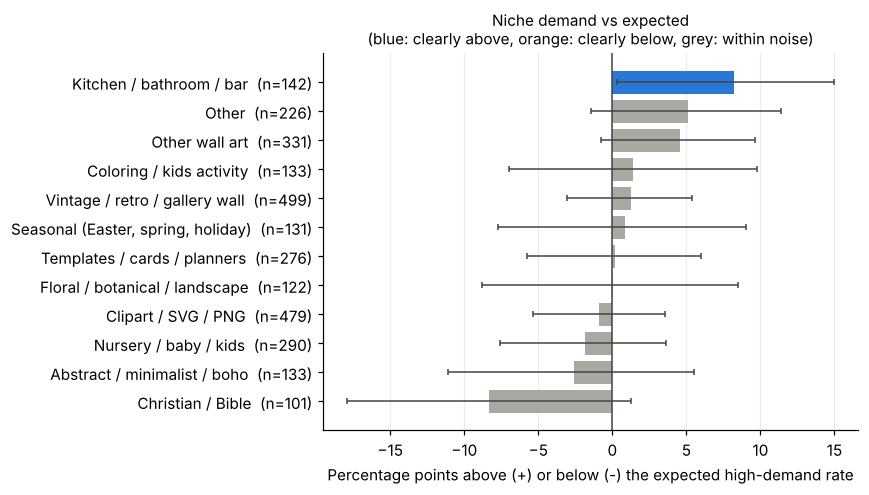

In [15]:
plot = niche.drop(index=["Unknown (no title)"]).sort_values("lift_pts")
colors = [BLUE if lo > 0 else (ORANGE if hi < 0 else GREY) for lo, hi in zip(plot.lift_lo, plot.lift_hi)]
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(plot))
ax.barh(y, plot.lift_pts, color=colors)
ax.errorbar(plot.lift_pts, y, xerr=[plot.lift_pts - plot.lift_lo, plot.lift_hi - plot.lift_pts], fmt="none", ecolor="#444", lw=1, capsize=2)
ax.axvline(0, color="#444", lw=1)
ax.set_yticks(y); ax.set_yticklabels([f"{n}  (n={int(l):,})" for n, l in zip(plot.index, plot.listings)])
ax.set_xlabel("Percentage points above (+) or below (-) the expected high-demand rate")
ax.set_title("Niche demand vs expected\n(blue: clearly above, orange: clearly below, grey: within noise)", fontsize=10)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(IMG_DIR / "niche_high_demand.png"); plt.show()

### 3.4 Competition vs demand by niche

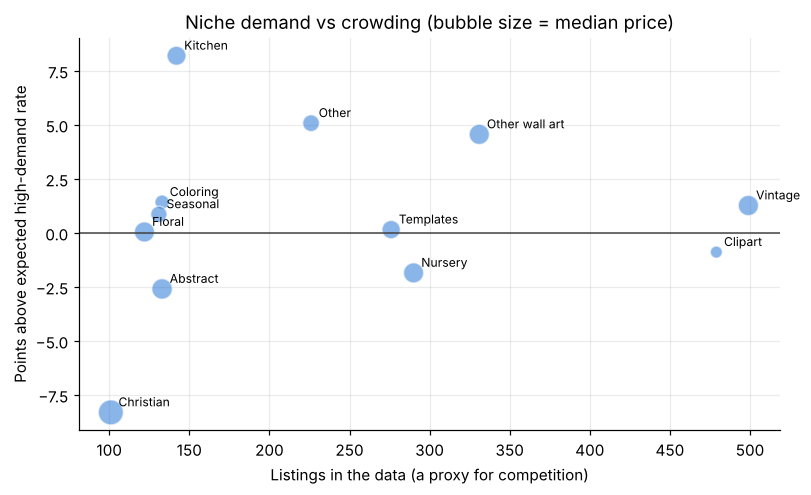

In [16]:
plot2 = niche.drop(index=["Unknown (no title)"])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(plot2.listings, plot2.lift_pts, s=plot2.median_price * 25, color=BLUE, alpha=.55, edgecolor="white")
ax.axhline(0, color="#444", lw=1)
for n, r in plot2.iterrows():
    ax.annotate(n.split(" (")[0].split(" /")[0], (r.listings, r.lift_pts), fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.set_xlabel("Listings in the data (a proxy for competition)"); ax.set_ylabel("Points above expected high-demand rate")
ax.set_title("Niche demand vs crowding (bubble size = median price)")
plt.tight_layout(); plt.savefig(IMG_DIR / "niche_bubble.png"); plt.show()

### 3.5 Price points

,listings,expected_rate,median_favorites,high_demand_rate,lift_pts,lift_lo,lift_hi,share_of_listings
price_band,,,,,,,,
up to $2,277,0.510,155.0,0.552,4.251,-1.637,9.995,0.087
$2-4,777,0.539,282.0,0.574,3.473,-0.032,6.905,0.243
$4-6,662,0.598,519.0,0.612,1.419,-2.348,5.057,0.207
$6-10,702,0.614,675.0,0.611,-0.275,-3.932,3.262,0.220
$10-20,490,0.606,819.0,0.578,-2.876,-7.293,1.421,0.154
over $20,284,0.592,1004.0,0.479,-11.314,-17.057,-5.514,0.089


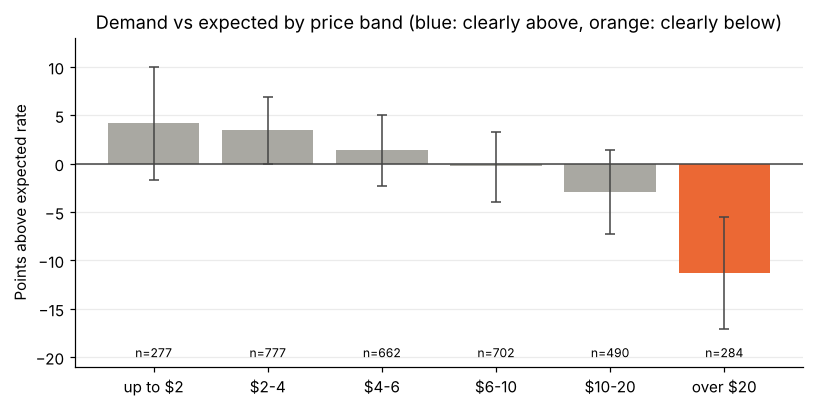

In [17]:
bins = [0, 2, 4, 6, 10, 20, np.inf]
labels = ["up to $2", "$2-4", "$4-6", "$6-10", "$10-20", "over $20"]
df["price_band"] = pd.cut(df["price"], bins=bins, labels=labels)
df_all["price_band"] = pd.cut(df_all["price"], bins=bins, labels=labels)
band = rate_table(df[df.price.notna()], "price_band")
band["share_of_listings"] = band.listings / band.listings.sum()
display(band.drop(columns=["high_demand_n", "ci_lo", "ci_hi", "median_price"]).round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(band))
bcol = [BLUE if lo > 0 else (ORANGE if hi < 0 else GREY) for lo, hi in zip(band.lift_lo, band.lift_hi)]
ax.bar(x, band.lift_pts, color=bcol)
ax.errorbar(x, band.lift_pts, yerr=[band.lift_pts - band.lift_lo, band.lift_hi - band.lift_pts], fmt="none", ecolor="#444", capsize=3, lw=1)
ax.axhline(0, color="#444", lw=1)
ax.set_ylim(-21, 13)
for i, n in enumerate(band.listings):
    ax.text(i, -20, f"n={n:,}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(band.index); ax.set_ylabel("Points above expected rate")
ax.set_title("Demand vs expected by price band (blue: clearly above, orange: clearly below)"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(IMG_DIR / "price_band_high_demand.png"); plt.show()

### 3.6 What separates high-demand listings from the rest?
I compare medians because reviews and favourites are heavily skewed (a few listings have tens of thousands). A bootstrap (NumPy, 2,000 resamples) gives a 95% interval for the ratio of medians. The comparison is done **separately inside each scrape**, because the two files differ in how many listings are high-demand and a pooled comparison would mix that in.

In [18]:
rng = np.random.default_rng(42)

def median_ratio_ci(a, b, n_boot=2000):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    ratios = np.empty(n_boot)
    for i in range(n_boot):
        ratios[i] = np.median(rng.choice(a, a.size)) / np.median(rng.choice(b, b.size))
    return np.median(a), np.median(b), np.percentile(ratios, [2.5, 97.5]), a.size, b.size

df["bundle_word"] = df["text"].fillna("").str.contains(r"bundle|\bset\b|mega|pack|\d{2,}\s*(?:prints|pieces)", regex=True)

METRICS = [("shop_reviews", "Shop reviews"), ("favorites", "Favorites"), ("item_reviews", "Item reviews"),
           ("price", "Price (USD)"), ("title_len", "Title length (chars)")]
rows = []
for src in ["2024-06", "2024-07"]:
    hi, lo = df[(df.source == src) & (df.high_demand == 1)], df[(df.source == src) & (df.high_demand == 0)]
    for col, label in METRICS:
        m_hi, m_lo, (c_lo, c_hi), n_hi, n_lo = median_ratio_ci(hi[col].astype(float), lo[col].astype(float))
        rows.append([label, src, m_hi, m_lo, m_hi / m_lo, c_lo, c_hi, n_hi, n_lo])
compare = pd.DataFrame(rows, columns=["metric", "source", "median_high", "median_rest", "ratio", "ci_lo", "ci_hi", "n_high", "n_rest"]).set_index(["metric", "source"])
display(compare.round(2))

txt = df[df.text.notna()]
share = pd.DataFrame({
    "variations_pct": 100 * df.groupby(["source", "high_demand"]).has_variants.mean(),
    "bundle_wording_pct": 100 * txt.groupby(["source", "high_demand"]).bundle_word.mean()}).round(1)
print("Share of listings with variations / bundle wording (high_demand 0 = rest, 1 = high):")
display(share)

,,median_high,median_rest,ratio,ci_lo,ci_hi,n_high,n_rest
metric,source,,,,,,,
Shop reviews,2024-06,917.50,784.00,1.17,0.94,1.54,866,840
Favorites,2024-06,379.00,252.00,1.50,1.26,1.80,977,1020
Item reviews,2024-06,32.00,22.00,1.45,1.22,1.74,866,840
Price (USD),2024-06,4.34,4.68,0.93,0.81,1.00,979,1020
Title length (chars),2024-06,136.00,136.00,1.00,0.99,1.00,632,679
Shop reviews,2024-07,982.00,806.50,1.22,0.88,1.70,759,256
Favorites,2024-07,1229.50,524.00,2.35,1.94,2.94,852,314
Item reviews,2024-07,28.00,19.00,1.47,1.12,1.81,759,256
Price (USD),2024-07,6.96,8.45,0.82,0.73,0.94,873,320


Share of listings with variations / bundle wording (high_demand 0 = rest, 1 = high):


variations_pct  bundle_wording_pct
source  high_demand                                    
2024-06 0                      10.2                25.2
        1                      11.7                23.3
2024-07 0                      15.0                41.1
        1                       8.5                35.5

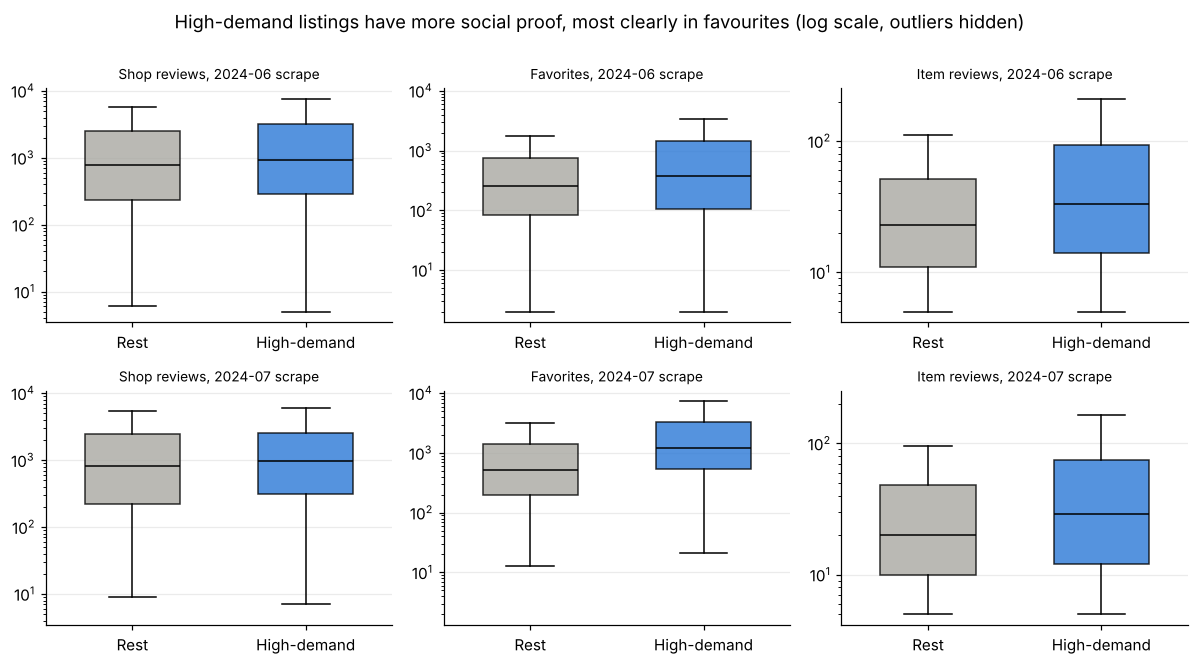

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey="col")
for r, src in enumerate(["2024-06", "2024-07"]):
    for ax, (col, lab) in zip(axes[r], [("shop_reviews", "Shop reviews"), ("favorites", "Favorites"), ("item_reviews", "Item reviews")]):
        g = df[df.source == src]
        data = [g.loc[g.high_demand == 0, col].dropna().astype(float) + 1, g.loc[g.high_demand == 1, col].dropna().astype(float) + 1]
        bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=.55, tick_labels=["Rest", "High-demand"])
        for patch, c in zip(bp["boxes"], [GREY, BLUE]): patch.set_facecolor(c); patch.set_alpha(.8)
        for med in bp["medians"]: med.set_color("black")
        ax.set_yscale("log"); ax.set_title(f"{lab}, {src} scrape", fontsize=9); ax.grid(axis="x", visible=False)
fig.suptitle("High-demand listings have more social proof, most clearly in favourites (log scale, outliers hidden)", y=1.0)
plt.tight_layout(); plt.savefig(IMG_DIR / "high_vs_rest.png", bbox_inches="tight"); plt.show()

### 3.7 Robustness checks

In [20]:
# 1. Does the niche ranking hold inside the June file alone (where titles are best recovered)?
jun_only = df[df.source == "2024-06"]
jun_base = jun_only.high_demand.mean()
r_jun = jun_only.groupby("niche").high_demand.agg(["mean", "size"]).rename(columns={"mean": "rate_june_only", "size": "n_june"})
r_jun["june_lift_pts"] = 100 * (r_jun.rate_june_only - jun_base)
cmp = niche[["listings", "lift_pts"]].join(r_jun).sort_values("lift_pts", ascending=False)
print(f"June-only base rate: {jun_base:.1%}")
display(cmp.round(2))

# 2. Add the no-badge listings back, counted as "not high-demand". Do the headline results survive?
df_all["niche"] = df_all["text"].map(tag_niche)
alt = rate_table(df_all, "niche")
alt_b = rate_table(df_all[df_all.price.notna()], "price_band")
print(f"All {len(df_all):,} listings: overall high-demand rate {df_all.high_demand.mean():.1%} (badge-only population: {df.high_demand.mean():.1%})")
display(alt.loc[["Kitchen / bathroom / bar", "Vintage / retro / gallery wall", "Seasonal (Easter, spring, holiday)", "Clipart / SVG / PNG"],
                ["listings", "high_demand_rate", "expected_rate", "lift_pts", "lift_lo", "lift_hi"]].round(3))
display(alt_b[["listings", "high_demand_rate", "lift_pts", "lift_lo", "lift_hi"]].round(3))

June-only base rate: 49.0%


,listings,lift_pts,rate_june_only,n_june,june_lift_pts
niche,,,,,
Kitchen / bathroom / bar,142,8.20,0.52,56,2.81
Other,226,5.08,0.54,206,5.39
Other wall art,331,4.56,0.53,212,4.33
Coloring / kids activity,133,1.43,0.51,129,2.19
Vintage / retro / gallery wall,499,1.27,0.47,221,-1.92
"Seasonal (Easter, spring, holiday)",131,0.86,0.47,95,-1.61
Templates / cards / planners,276,0.15,0.49,233,0.38
Floral / botanical / landscape,122,0.04,0.52,84,3.41
Clipart / SVG / PNG,479,-0.89,0.48,468,-0.68


All 3,968 listings: overall high-demand rate 46.7% (badge-only population: 58.0%)


,listings,high_demand_rate,expected_rate,lift_pts,lift_lo,lift_hi
niche,,,,,,
Kitchen / bathroom / bar,148,0.689,0.511,17.842,9.986,24.741
Vintage / retro / gallery wall,533,0.597,0.499,9.764,5.545,13.846
"Seasonal (Easter, spring, holiday)",209,0.354,0.436,-8.218,-14.385,-1.524
Clipart / SVG / PNG,559,0.417,0.400,1.701,-2.316,5.831


,listings,high_demand_rate,lift_pts,lift_lo,lift_hi
price_band,,,,,
up to $2,282,0.543,3.329,-2.504,9.048
$2-4,790,0.565,3.201,-0.279,6.619
$4-6,680,0.596,1.536,-2.196,5.161
$6-10,721,0.595,0.193,-3.431,3.717
$10-20,500,0.566,-2.046,-6.424,2.232
over $20,298,0.456,-12.176,-17.740,-6.501


## 4. SQL section (SQLite)
The cleaned table is loaded into an in-memory SQLite database and the same business questions are answered with SQL: a niche league table using a window function, a price-band share table, and a niche × price-band cross-tab using a CTE. The numbers should match section 3.

In [21]:
conn = sqlite3.connect(":memory:")
sql_df = df.drop(columns=["text", "title", "price_band", "listed_date", "carts", "views_24h", "bought_recent", "demand_raw"]).copy()
sql_df["has_variants"] = sql_df["has_variants"].astype(int); sql_df["bundle_word"] = sql_df["bundle_word"].astype(int)
sql_df.to_sql("listings", conn, index=False, if_exists="replace")
print(pd.read_sql("SELECT COUNT(*) AS rows_loaded FROM listings", conn).to_string(index=False))

def q(sql): return pd.read_sql(sql, conn)

 rows_loaded
        3192


In [22]:
# Q1: niche league table (niches with 100+ listings), ranked by points above the source-adjusted expected rate.
# A CTE gives each source's own base rate; a window function ranks the result.
q('''
WITH src AS (SELECT source, AVG(high_demand) AS base FROM listings GROUP BY source)
SELECT l.niche,
       COUNT(*)                                          AS listings,
       ROUND(100.0 * AVG(l.high_demand), 1)              AS high_demand_pct,
       ROUND(100.0 * AVG(s.base), 1)                     AS expected_pct,
       ROUND(100.0 * (AVG(l.high_demand) - AVG(s.base)), 1) AS lift_pts,
       ROUND(AVG(l.price), 2)                            AS avg_price,
       RANK() OVER (ORDER BY AVG(l.high_demand) - AVG(s.base) DESC) AS lift_rank
FROM listings l JOIN src s ON s.source = l.source
WHERE l.niche <> 'Unknown (no title)'
GROUP BY l.niche
HAVING COUNT(*) >= 100
ORDER BY lift_rank
''')

,niche,listings,high_demand_pct,expected_pct,lift_pts,avg_price,lift_rank
0,Kitchen / bathroom / bar,142,71.8,63.6,8.2,7.53,1
1,Other,226,56.2,51.1,5.1,8.14,2
2,Other wall art,331,62.2,57.7,4.6,9.58,3
3,Coloring / kids activity,133,51.1,49.7,1.4,4.50,4
4,Vintage / retro / gallery wall,499,63.7,62.5,1.3,10.10,5
5,"Seasonal (Easter, spring, holiday)",131,56.5,55.6,0.9,7.31,6
6,Templates / cards / planners,276,52.9,52.7,0.2,22.23,7
7,Floral / botanical / landscape,122,56.6,56.5,0.0,13.14,8
8,Clipart / SVG / PNG,479,48.6,49.5,-0.9,3.09,9
9,Nursery / baby / kids,290,59.3,61.2,-1.8,8.70,10


In [23]:
# Q2: price bands, with each band's share of all priced listings versus its share of all high-demand listings (raw rates, not source-adjusted)
q('''
WITH banded AS (
  SELECT CASE WHEN price <= 2  THEN '1 up to $2'
              WHEN price <= 4  THEN '2 $2-4'
              WHEN price <= 6  THEN '3 $4-6'
              WHEN price <= 10 THEN '4 $6-10'
              WHEN price <= 20 THEN '5 $10-20'
              ELSE                  '6 over $20' END AS band,
         high_demand
  FROM listings WHERE price IS NOT NULL
)
SELECT band,
       COUNT(*)                                               AS listings,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)     AS pct_of_listings,
       ROUND(100.0 * SUM(high_demand) / SUM(SUM(high_demand)) OVER (), 1) AS pct_of_high_demand,
       ROUND(100.0 * AVG(high_demand), 1)                     AS high_demand_pct
FROM banded GROUP BY band ORDER BY band
''')

,band,listings,pct_of_listings,pct_of_high_demand,high_demand_pct
0,1 up to $2,277,8.7,8.3,55.2
1,2 $2-4,777,24.3,24.1,57.4
2,3 $4-6,662,20.7,21.9,61.2
3,4 $6-10,702,22.0,23.2,61.1
4,5 $10-20,490,15.4,15.3,57.8
5,6 over $20,284,8.9,7.3,47.9


In [24]:
# Q3: strongest niche x price-band cells, as points above expected (CTE, minimum 40 listings per cell)
sql_cross = q('''
WITH src AS (SELECT source, AVG(high_demand) AS base FROM listings WHERE price IS NOT NULL GROUP BY source),
cell AS (
  SELECT l.niche,
         CASE WHEN l.price <= 4 THEN 'a up to $4' WHEN l.price <= 10 THEN 'b $4-10' ELSE 'c over $10' END AS band,
         COUNT(*) AS listings, AVG(l.high_demand) AS rate, AVG(s.base) AS expected
  FROM listings l JOIN src s ON s.source = l.source
  WHERE l.price IS NOT NULL AND l.niche <> 'Unknown (no title)'
  GROUP BY l.niche, band
)
SELECT niche, band, listings, ROUND(100.0 * rate, 1) AS high_demand_pct, ROUND(100.0 * (rate - expected), 1) AS lift_pts
FROM cell WHERE listings >= 40
ORDER BY rate - expected DESC LIMIT 8
''')
sql_cross

,niche,band,listings,high_demand_pct,lift_pts
0,Other,a up to $4,90,62.2,11.9
1,Nursery / baby / kids,a up to $4,51,66.7,9.6
2,Templates / cards / planners,a up to $4,93,60.2,8.6
3,Other wall art,a up to $4,72,63.9,8.2
4,Coloring / kids activity,b $4-10,42,57.1,8.2
5,"Seasonal (Easter, spring, holiday)",a up to $4,53,60.4,6.4
6,Other wall art,b $4-10,165,63.6,4.8
7,Kitchen / bathroom / bar,b $4-10,91,69.2,4.8


## 5. Findings and recommendation
Every figure below is produced by the code above. The next cell prints them again from the data so they can be checked against the text.

In [25]:
# Numbers quoted in the findings (recomputed here so the text can be checked against the data)
f = lambda x, n=1: round(float(x), n)
N = lambda name: niche.loc[name]
key = {
 "raw_rows": log[0][1], "unique_listings": len(df_all), "duplicates_removed": log[0][1] - len(df_all),
 "analysis_rows_with_badge": len(df), "high_demand_n": int(df.high_demand.sum()),
 "priced_rows": int(df.price.notna().sum()), "text_coverage_pct": f(100 * df.text.notna().mean()),
 "overall_high_demand_pct": f(100 * df.high_demand.mean()),
}
for tag, name in [("kitchen_bath", "Kitchen / bathroom / bar"), ("vintage", "Vintage / retro / gallery wall"), ("nursery", "Nursery / baby / kids"),
                  ("clipart", "Clipart / SVG / PNG"), ("seasonal", "Seasonal (Easter, spring, holiday)"), ("coloring", "Coloring / kids activity"),
                  ("christian", "Christian / Bible")]:
    r = N(name)
    key[tag] = {"n": int(r.listings), "rate_pct": f(100 * r.high_demand_rate), "expected_pct": f(100 * r.expected_rate),
                "lift_pts": f(r.lift_pts), "lift_ci": (f(r.lift_lo), f(r.lift_hi)), "median_price": f(r.median_price, 2)}
for name, r in band.iterrows():
    key[f"band {name}"] = {"n": int(r.listings), "rate_pct": f(100 * r.high_demand_rate), "lift_pts": f(r.lift_pts), "lift_ci": (f(r.lift_lo), f(r.lift_hi))}
key["share_listings_4_to_10_pct"] = f(100 * band.loc[["$4-6", "$6-10"], "listings"].sum() / band.listings.sum())
for src in ["2024-06", "2024-07"]:
    for lab, c in [("shop_reviews", "Shop reviews"), ("favorites", "Favorites"), ("item_reviews", "Item reviews"), ("price", "Price (USD)")]:
        r = compare.loc[(c, src)]
        key[f"{lab} {src}"] = {"median_high": f(r.median_high, 2), "median_rest": f(r.median_rest, 2), "ratio": f(r.ratio, 2),
                               "ci": (f(r.ci_lo, 2), f(r.ci_hi, 2)), "n_high": int(r.n_high), "n_rest": int(r.n_rest)}
key["clipart_share_of_listings_pct"] = f(100 * N("Clipart / SVG / PNG").listings / len(df))
a = alt.loc["Vintage / retro / gallery wall"]; k2 = alt.loc["Kitchen / bathroom / bar"]
key["if_no_badge_rows_counted_as_rest"] = {"vintage_lift_pts": f(a.lift_pts), "kitchen_lift_pts": f(k2.lift_pts),
                                           "over20_lift_pts": f(alt_b.loc["over $20", "lift_pts"])}
for k, v in key.items(): print(f"{k:28s} {v}")

raw_rows                     4632
unique_listings              3968
duplicates_removed           664
analysis_rows_with_badge     3192
high_demand_n                1852
priced_rows                  3192
text_coverage_pct            89.7
overall_high_demand_pct      58.0
kitchen_bath                 {'n': 142, 'rate_pct': 71.8, 'expected_pct': 63.6, 'lift_pts': 8.2, 'lift_ci': (0.3, 14.9), 'median_price': 6.23}
vintage                      {'n': 499, 'rate_pct': 63.7, 'expected_pct': 62.5, 'lift_pts': 1.3, 'lift_ci': (-3.0, 5.4), 'median_price': 7.06}
nursery                      {'n': 290, 'rate_pct': 59.3, 'expected_pct': 61.2, 'lift_pts': -1.8, 'lift_ci': (-7.6, 3.6), 'median_price': 6.96}
clipart                      {'n': 479, 'rate_pct': 48.6, 'expected_pct': 49.5, 'lift_pts': -0.9, 'lift_ci': (-5.3, 3.6), 'median_price': 2.52}
seasonal                     {'n': 131, 'rate_pct': 56.5, 'expected_pct': 55.6, 'lift_pts': 0.9, 'lift_ci': (-7.7, 9.0), 'median_price': 4.52}
coloring    

## Findings

All figures use the 3,192 listings that show a demand badge (1,852 of them, 58.0%, are high-demand). Rates are compared with an *expected* rate for each listing's own scrape, and intervals are 95%. The checks that these hold up are in section 3.7.

**1. Price: listings over $20 are the clear weak spot, and nothing else in the price range stands out.**
Listings priced over $20 are high-demand 47.9% of the time, **11.3 percentage points below expected** (95% CI -17.1 to -5.5, n=284). No band up to $20 differs clearly from expected. The highest raw rates are in the $4-6 band (61.2%) and the $6-10 band (61.1%), and 42.7% of all listings sit between $4 and $10. Within each scrape, high-demand listings also have a slightly lower median price: $4.34 vs $4.68 in June (ratio 0.93, CI 0.81-1.00) and $6.96 vs $8.45 in July (ratio 0.82, CI 0.73-0.94).

**2. Niches: only kitchen / bathroom / bar wall art is above expected, and most other niches cannot be told apart.**
Kitchen / bathroom / bar listings are high-demand 71.8% of the time vs 63.6% expected, **+8.2 points** (CI 0.3 to 14.9, n=142). That is a small sample with a lower bound close to zero, and inside the June file alone the gap shrinks to +2.8 points (n=56). Every other tagged niche has an interval that includes zero. The weakest is Christian / Bible at -8.3 points (CI -17.9 to 1.2, n=101), which is suggestive, not conclusive. A **vintage / retro / gallery wall** edge appears only if listings with no demand badge are counted as low-demand (+9.8 points). It vanishes in the badge-only analysis (+1.3 points, CI -3.0 to 5.4, n=499), so I do not claim one.

**3. What separates high-demand listings is social proof, not price or title.**
Median favourites are higher for high-demand listings in both scrapes: 379 vs 252 in June (ratio 1.50, CI 1.26-1.80) and about 1,230 vs 524 in July (ratio 2.35, CI 1.94-2.94). Item reviews show the same pattern (ratios 1.45 and 1.47). Shop-level reviews are not clearly different (ratios 1.17 and 1.22, both intervals include 1.0). Title length is identical (median 136 vs 136 characters in June, 137 vs 137 in July), and neither variations nor bundle wording differ in a consistent direction.

**4. Clipart / SVG / PNG is a crowded, cheap niche with no demand premium.**
It is the largest tagged niche, **15.0% of badged listings** (n=479), with a median price of $2.52 versus $7.00 for general wall art, and its high-demand rate is on par with expected (48.6% vs 49.5%, -0.9 points, CI -5.3 to 3.6).

## Recommendation
1. **Enter through kitchen / bathroom / bar wall art priced at $4-10.** It is the only niche above expectation, and within the $4-10 band it reaches 69.2% high-demand (n=91). Treat it as a hypothesis to test with a small batch: the sample is modest and the edge is smaller in the June file alone.
2. **Keep single-listing prices at or below $20.** Above that, demand badges are clearly rarer.
3. **Do not compete as a pure low-price clipart shop.** It is the most crowded niche, with no demand advantage to offset the $2.52 median price.
4. **Plan for social proof from day one.** Favourites and item reviews are what high-demand listings have more of, so launch with photography, a tight title and a push for early favourites and reviews, rather than relying on price or title tweaks.

## Limitations
- "High-demand" is Etsy's live badge at scrape time (20+ carts or recent purchases), not sales or revenue. It is a proxy for demand.
- Only two snapshots from mid-2024 are used, so seasonality and today's market are not covered.
- Niches come from title keywords, with no category field. About 10% of badged listings have no usable text and sit in "Unknown".
- Favourites and reviews are associated with demand badges; the data cannot say which causes which.
- Listings with no badge (776) could not be classified, so they are excluded from the main analysis and tested in section 3.7.

## 6. Anonymised sample export
The sample drops everything that could identify a shop or listing: no URLs, titles, shop names, listing IDs or exact review counts. Numeric fields are banded, price is rounded, and rows are a random draw with a fixed seed. A scan confirms that no text field contains a URL or a long free-text string.

In [26]:
def band_counts(s, edges, labels):
    return pd.cut(s.astype(float), bins=edges, labels=labels, right=True)

edges = [-1, 0, 10, 100, 1_000, 10_000, np.inf]
lab = ["0", "1-10", "11-100", "101-1k", "1k-10k", "10k+"]
sample = pd.DataFrame({
    "source": df["source"],
    "niche": df["niche"],
    "price_usd_rounded": df["price"].round(0),
    "price_band": df["price_band"].astype("string"),
    "has_variants": df["has_variants"].astype(int),
    "demand_tier": df["demand_tier"],
    "high_demand": df["high_demand"],
    "item_reviews_band": band_counts(df["item_reviews"], edges, lab).astype("string"),
    "shop_reviews_band": band_counts(df["shop_reviews"], edges, lab).astype("string"),
    "favorites_band": band_counts(df["favorites"], edges, lab).astype("string"),
    "bundle_word": df["bundle_word"].astype(int),
}).sample(n=300, random_state=42).reset_index(drop=True)

sample.to_csv(SAMPLE_DIR / "anonymised_sample.csv", index=False)

# Safety scan: no URL-like or long free-text values anywhere in the export
txt = sample.select_dtypes(include=["object", "string"])
assert not txt.apply(lambda c: c.astype(str).str.contains(r"http|www\.|etsy", case=False)).any().any()
assert txt.apply(lambda c: c.astype(str).str.len().max()).max() < 40
print("Sample written:", sample.shape, "- scan passed (no URLs, no long text)")
sample.head()

Sample written: (300, 11) - scan passed (no URLs, no long text)


,source,niche,price_usd_rounded,price_band,has_variants,demand_tier,high_demand,item_reviews_band,shop_reviews_band,favorites_band,bundle_word
0,2024-07,Unknown (no title),6.0,$6-10,0,Views only,0,11-100,101-1k,101-1k,0
1,2024-07,Unknown (no title),6.0,$6-10,0,In 20+ carts,1,11-100,101-1k,1k-10k,0
2,2024-07,Vintage / retro / gallery wall,9.0,$6-10,1,Views only,0,11-100,1k-10k,1k-10k,0
3,2024-07,Vintage / retro / gallery wall,7.0,$6-10,0,In 20+ carts,1,101-1k,101-1k,10k+,1
4,2024-07,Christian / Bible,12.0,$10-20,0,In 20+ carts,1,11-100,1k-10k,1k-10k,0


## CV bullet
> **Accomplished** a data-backed niche and pricing recommendation for Etsy printable wall art, **as measured by** 3,192 demand-tagged listings analysed (cleaned from 4,632 raw scraped rows, 664 duplicates removed) and a finding that listings over $20 were 11.3 points less likely to show a high-demand badge than expected (95% CI -17.1 to -5.5), **by** cleaning two scraped datasets in pandas, bootstrapping median comparisons with NumPy, charting in Matplotlib and answering the business questions with SQL in SQLite.